# Projekt 1. Eksploracyjna analiza wybranego zbioru danych 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

## 1. Wstęp
Tematem niniejszego projektu jest eksploracyjna analiza danych medycznych dotyczących pacjentów, u których zaobserwowano lub nie zaobserwowano wystąpienie udaru mózgu. 
Celem pracy jest opisanie struktury zbioru danych oraz identyfikacja zależności pomiędzy wybranymi zmiennymi przy użyciu metod statystyki opisowej i wizualizacji danych.
Zbiór danych został wybrany ze względu na jego medyczny charakter i praktyczne znaczenie - udar mózgu stanowi jedno z najpoważniejszych zagrożeń zdrowotnych na świecie. Według danych Światowej Organizacji Zdrowia w 2021 r. udar mózgu był trzecią najczęstszą przyczyną zgonów i niepełnosprawności na świecie [*https://www.who.int/news-room/fact-sheets/detail/stroke*]. Analiza czynników ryzyka może pomóc w lepszym zrozumieniu tego zjawiska.

In [2]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2.  Opis zbioru danych

Zbiór danych wybrany do analizy: **Stroke Prediction Dataset**

Źródło: Kaggle - *https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset*. 
<br>Pierwotne źródło danych medycznych jest poufne - zbiór udostępniony jest wyłącznie w celach edukacyjnych, co jest zgodne z przeznaczeniem niniejszego projektu.

Liczba obserwacji: 5110

Liczba zmiennych: 12 

Zbiór zawiera dane dotyczące pacjentów opisanych przez cechy demograficzne (wiek, płeć, miejsce zamieszkania), społeczne (stan cywilny, typ zatrudnienia) oraz kliniczne (nadciśnienie, choroba serca, poziom glukozy, BMI, status palenia). Każda obserwacja odpowiada jednemu pacjentowi, a zmienna docelowa 'stroke' wskazuje, czy u danego pacjenta doszło do udaru mózgu.

**Wstępne rozpoznanie**

Rozmiar zbioru

In [3]:
print(f"Liczba obserwacji (wierszy): {df.shape[0]}")
print(f"Liczba zmiennych (kolumn): {df.shape[1]}")

Liczba obserwacji (wierszy): 5110
Liczba zmiennych (kolumn): 12


Typy danych

In [4]:
df.dtypes

id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

Podstawowe info

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


**Podział i opis zmiennych**

In [6]:
zm_jakosciowe = [
    "gender", "hypertension", "heart_disease",
    "ever_married", "work_type", "Residence_type",
    "smoking_status", "stroke"
]

zm_ilosciowe = ["age", "avg_glucose_level", "bmi"]

print("\n Zmienne jakościowe")
for col in zm_jakosciowe:
    print(f"\nZmienna: {col}")
    print(f"Kardynalność: {df[col].nunique()}")
    print(f"Uniklane wartości: {df[col].unique()}")

print("\nZmienne ilościowe")
print(df[zm_ilosciowe].describe())


 Zmienne jakościowe

Zmienna: gender
Kardynalność: 3
Uniklane wartości: ['Male' 'Female' 'Other']

Zmienna: hypertension
Kardynalność: 2
Uniklane wartości: [0 1]

Zmienna: heart_disease
Kardynalność: 2
Uniklane wartości: [1 0]

Zmienna: ever_married
Kardynalność: 2
Uniklane wartości: ['Yes' 'No']

Zmienna: work_type
Kardynalność: 5
Uniklane wartości: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Zmienna: Residence_type
Kardynalność: 2
Uniklane wartości: ['Urban' 'Rural']

Zmienna: smoking_status
Kardynalność: 4
Uniklane wartości: ['formerly smoked' 'never smoked' 'smokes' 'Unknown']

Zmienna: stroke
Kardynalność: 2
Uniklane wartości: [1 0]

Zmienne ilościowe
               age  avg_glucose_level          bmi
count  5110.000000        5110.000000  4909.000000
mean     43.226614         106.147677    28.893237
std      22.612647          45.283560     7.854067
min       0.080000          55.120000    10.300000
25%      25.000000          77.245000    23.500000
50%   

**Zmienne jakościowe:**

<br>**gender** - płeć pacjenta
- zmienna jakościowa nominalna
- kardynalność: 3

Kategorie: Male (mężczyzna), Female (kobieta), Other. Kategoria Other występuje tylko w jednej obserwacji, co zostanie omówione w sekcji przygotowania danych. Płeć może różnicować ryzyko i charakter udaru.

<br>**hypertension** - informacja o występowaniu nadciśnienia tętniczego
- zmienna jakościowa dychotomiczna
- kardynalność: 2

Kategorie: 0 (brak nadciśnienia), 1 (nadciśnienie). Nadciśnienie jest jednym z najsilniejszych czynników ryzyka udaru mózgu.

<br>**heart_disease** - informacja o występowaniu choroby serca
- zmienna jakościowa dychotomiczna
- kardynalność: 2

Kategorie: 0 (brak choroby serca), 1 (choroba serca). Choroby serca znacząco zwiększają ryzyko udaru.

<br>**ever_married** - informacja o tym, czy pacjent kiedykolwiek był w związku małżeńskim
- zmienna jakościowa dychotomiczna
- kardynalność: 2

Kategorie: Yes (tak), No (nie). Zmienna może pośrednio odzwierciedlać wiek i poziom poczucia stabilności życia pacjenta.

<br>**work_type** - typ zatrudnienia pacjenta
- zmienna jakościowa nominalna
- kardynalność: 5
Kategorie: Private (sektor prywatny), Self-employed (samozatrudnienie), Govt_job (sektor publiczny), children (dziecko, niepracujące), Never_worked (nigdy nie pracował). Typ pracy może być związany z poziomem stresu i stylem życia, które wpływają na ryzyko udaru.

<br>**Residence_type** - typ miejsca zamieszkania pacjenta
- zmienna jakościowa dychotomiczna
- kardynalność: 2

Kategorie: Urban (miasto), Rural (wieś). Może odzwierciedlać różnice w dostępie do opieki medycznej, narażeniu na zanieczyszczenia czy też wskazywac na różny styl życia.

<br>**smoking_status** - palenie tytoniu
- zmienna jakościowa nominalna
- kardynalność: 4

Kategorie: never smoked (nigdy nie palił), formerly smoked (palił w przeszłości), smokes (aktualnie pali), Unknown (brak danych). Kategoria Unknown nie jest brakiem w sensie technicznym (NaN), lecz osobną wartością - decyzja o jej traktowaniu zostanie omówiona w sekcji przygotowania danych. Palenie tytoniu jest udokumentowanym czynnikiem ryzyka chorób naczyniowo-mózgowych.

<br>**stroke** - zmienna docelowa
- zmienna jakościowa dychotomiczna
- kardynalność: 2

Informuje czy u pacjenta wystąpił udar mózgu. Kategorie: 0 (brak udaru), 1 (udar).

<br><br>
**Zmienne ilościowe:**

<br>**age** - wiek pacjenta 
- zmienna ilościowa
- jednostka: lata

Wiek jest jednym z kluczowych czynników ryzyka udaru - ryzyko wzrasta istotnie wraz z wiekiem.

<br>**avg_glucose_level** - średni poziom glukozy we krwi pacjenta
- zmienna ilościowa 
- jednostka*: mg/dL

Podwyższony poziom glukozy jest charakterystyczny dla cukrzycy, która jest uznanym czynnikiem ryzyka udaru mózgu.

<br>**bmi** - wskaźnik masy ciała
- zmienna ilościowa, 
- jednostka*: kg/m^2

Wskażnik BMI obliczany jest jako stosunek masy ciała do kwadratu wzrostu. Wysokie BMI związane jest z otyłością, która zwiększa ryzyko chorób układu krążenia, w tym udaru.

\* *Jednostki nie zostały podane w źródle. Dla BMI wynikają z definicji wskaźnika (kg/m^2), natomiast dla poziomu glukozy zostały określone na podstawie skali wartości w zbiorze (mg/dL).*

## 3. Przygotowanie danych 

**3.1 Braki danych**

In [7]:
braki = df.isnull().sum()
braki_proc = (braki / len(df) * 100).round(2)
print(pd.DataFrame({"Braki": braki, "% braków": braki_proc}))

                   Braki  % braków
id                     0      0.00
gender                 0      0.00
age                    0      0.00
hypertension           0      0.00
heart_disease          0      0.00
ever_married           0      0.00
work_type              0      0.00
Residence_type         0      0.00
avg_glucose_level      0      0.00
bmi                  201      3.93
smoking_status         0      0.00
stroke                 0      0.00


Sprawdzenie czy braki w zmiennej **bmi** mogą być powiązane z innymi zmiennymi

In [8]:
print("Braki w bmi vs udar")
counts = df.groupby(df['bmi'].isna())['stroke'].value_counts()
percent = df.groupby(df['bmi'].isna())['stroke'].value_counts(normalize=True)*100

braki_table = pd.DataFrame({
    'Liczba': counts,
    'Udział %': percent.round(2) 
})
print(braki_table)

print("\nBraki w bmi vs gender")
counts = df.groupby(df['bmi'].isna())['gender'].value_counts()
percent = df.groupby(df['bmi'].isna())['gender'].value_counts(normalize=True)*100

braki_table2 = pd.DataFrame({
    'Liczba': counts,
    'Udział %': percent.round(2) 
})
print(braki_table2)

print("\nBraki w bmi vs wiek")
print(df.groupby(df['bmi'].isna())['age'].describe())

Braki w bmi vs udar
              Liczba  Udział %
bmi   stroke                  
False 0         4700     95.74
      1          209      4.26
True  0          161     80.10
      1           40     19.90

Braki w bmi vs gender
              Liczba  Udział %
bmi   gender                  
False Female    2897     59.01
      Male      2011     40.97
      Other        1      0.02
True  Male       104     51.74
      Female      97     48.26

Braki w bmi vs wiek
        count       mean        std   min   25%   50%   75%   max
bmi                                                              
False  4909.0  42.865374  22.555115  0.08  25.0  44.0  60.0  82.0
True    201.0  52.049154  22.276181  0.48  37.0  58.0  71.0  82.0


Zmienna **bmi** zawiera 201 braków danych, co stanowi 3,93% wszystkich obserwacji (teoretycznie jest to wartość poniżej powszechnie przyjętego progu 5%, przy którym dopuszczalne jest ignorowanie/usunięcie niekompletnych wierszy). Mimo to zbadano losowość braków. Analiza wykazała, że braki nie mają charakteru w pełni losowego. Pacjenci z brakującym BMI są przeciętnie starsi oraz znacznie częściej doświadczyli udaru - 20% wobec 4% w grupie z dostępnym BMI. Biorąc pod uwagę, że przypadki udaru stanowią niewielką część całego zbioru, usunięcie 40 spośród nich - co stanowiłoby ok. 16% wszystkich przypadków udaru - nieproporcjonalnie zmniejszyłoby reprezentację tej grupy.
Ponieważ analiza ma charakter opisowy, zdecydowano o pozostawieniu braków bez imputacji. Wszystkie statystyki i wizualizacje dla zmiennej **bmi** zostały obliczone na dostępnych obserwacjach, co stanowi ok. 96% zbioru.

**3.2 Wartości nietypowe lub podejrzane**

Zmienne ilościowe 

In [9]:
print(df[zm_ilosciowe].describe())

               age  avg_glucose_level          bmi
count  5110.000000        5110.000000  4909.000000
mean     43.226614         106.147677    28.893237
std      22.612647          45.283560     7.854067
min       0.080000          55.120000    10.300000
25%      25.000000          77.245000    23.500000
50%      45.000000          91.885000    28.100000
75%      61.000000         114.090000    33.100000
max      82.000000         271.740000    97.600000

W badanym zbiorze występują obserwacje skrajne, jednak wszystkie mieszczą się w realistycznych granicach medycznych (np. bardzo niski lub wysoki BMI, wysoki poziom glukozy czy bardzo młody wiek pacjenta).
W związku z tym nie zidentyfikowano wartości jednoznacznie błędnych ani niemożliwych. Zdecydowano się pozostawić wszystkie obserwacje w zbiorze danych, ponieważ wartości skrajne mogą mieć istotne znaczenie analityczne.

Zmienna **gender** - kategoria "Other"

In [10]:
print(df['gender'].value_counts())
display(df[df['gender'] == 'Other'])

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
3116,56156,Other,26.0,0,0,No,Private,Rural,143.33,22.4,formerly smoked,0


Kategoria "Other" w zmiennej gender występuje tylko w jednej obserwacji. Pojedyncza obserwacja nie tworzy reprezentatywnej grupy analitycznej i mogłaby zaburzać obliczenia grupowe, dlatego rekord ten został usunięty.

In [11]:
df = df[df['gender'] != 'Other']
print(df['gender'].value_counts())

gender
Female    2994
Male      2115
Name: count, dtype: int64


Zmienna **smoking_status** - kategoria "Unknown"

In [12]:
counts = df['smoking_status'].value_counts()
percent = df['smoking_status'].value_counts(normalize=True) * 100

smoking_table = pd.DataFrame({
    'Liczba': counts,
    'Udział %': percent.round(2) 
})

print(smoking_table)

                 Liczba  Udział %
smoking_status                   
never smoked       1892     37.03
Unknown            1544     30.22
formerly smoked     884     17.30
smokes              789     15.44


Kategoria "Unknown" w zmiennej **smoking_status** oznacza brak informacji o statusie palenia - nie jest to brak danych techniczny (NaN), lecz celowo utworzona kategoria. Ze względu na jej liczebność (ok. 30% obserwacji) zdecydowano o pozostawieniu jej jako odrębnej grupy w analizie.

**3.3 Przekształcenia danych**

Nie było konieczne przeprowadzanie zaawansowanych przekształceń danych. Kodowanie zmiennych jakosciowych nie było wymagane, ponieważ analiza ma charakter eksploracyjny (głównie tworzenie tabel częstości i wykresów) i nie obejmuje budowy modeli predykcyjnych.

**3.4 Usunięcie zmiennych**

Zmienna id została usunięta ze zbioru danych, ponieważ pełni wyłącznie funkcję technicznego identyfikatora obserwacji i nie niesie informacji merytorycznej dotyczącej analizowanego problemu, jakim jest identyfikacja czynników ryzyka udaru.

In [13]:
df = df.drop(columns=['id'])

## 4. Statystyki opisowe

**4.1 Zmienne ilościowe**

In [14]:
def statystyki_ilosciowe(df, col):
    zm = df[col].dropna()
    dominanta = zm.mode()[0]
    Q1 = zm.quantile(0.25)
    Q3 = zm.quantile(0.75)
    
    wyniki = {
        'Średnia': round(zm.mean(), 2),
        'Mediana': round(zm.median(), 2),
        'Dominanta': round(dominanta, 2),
        'Minimum': round(zm.min(), 2),
        'Maksimum': round(zm.max(), 2),
        'Rozstęp': round(zm.max() - zm.min(), 2),
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(Q3 - Q1, 2),
        'Wariancja': round(zm.var(), 2),
        'Odch. standardowe': round(zm.std(), 2),
        'Współ. zmienności (%)': round(zm.std() / zm.mean() * 100, 2),
        'Skośność': round(zm.skew(), 2),
        'Kurtoza': round(zm.kurtosis(), 2),
    }
    return pd.Series(wyniki, name=col)

tabela = pd.concat([
    statystyki_ilosciowe(df, 'age'),
    statystyki_ilosciowe(df, 'avg_glucose_level'),
    statystyki_ilosciowe(df, 'bmi')
], axis=1)

print(tabela)

                          age  avg_glucose_level    bmi
Średnia                 43.23             106.14  28.89
Mediana                 45.00              91.88  28.10
Dominanta               78.00              93.88  28.70
Minimum                  0.08              55.12  10.30
Maksimum                82.00             271.74  97.60
Rozstęp                 81.92             216.62  87.30
Q1                      25.00              77.24  23.50
Q3                      61.00             114.09  33.10
IQR                     36.00              36.85   9.60
Wariancja              511.37            2050.73  61.69
Odch. standardowe       22.61              45.29   7.85
Współ. zmienności (%)   52.31              42.67  27.18
Skośność                -0.14               1.57   1.06
Kurtoza                 -0.99               1.68   3.36


Interpretacja statystyk:

**age** - wiek pacjenta

Średni wiek pacjentów wynosi 43,23 lata, przy medianie 45 lat - zbliżone wartości sugerują względną symetrię rozkładu, co potwierdza skośność bliska zeru (-0,14). Zbiór obejmuje bardzo szeroki przedział wiekowy - od niemowląt (0,08 roku) do osób starszych (82 lata), co daje rozstęp niemal 82 lat. Połowa pacjentów mieści się w przedziale 25-61 lat. Odchylenie standardowe wynosi 22,61 roku, a współczynnik zmienności 52,31%, co wskazuje na duże zróżnicowanie wieku w zbiorze. Kurtoza -0,99 oznacza rozkład spłaszczony względem normalnego - wartości są równomierniej rozłożone, bez wyraźnego szczytu. Dominanta wynosi 78 lat, co może świadczyć o zwiększonej reprezentacji starszych pacjentów.

<br>**avg_glucose_level** - średni poziom glukozy [mg/dL]

Średni poziom glukozy wynosi 106,14 mg/dL, jednak mediana jest wyraźnie niższa - 91,88 mg/dL. Różnica między średnią a medianą wskazuje na prawostronną skośność rozkładu (skośność = 1,57), co oznacza że część pacjentów ma bardzo wysokie wartości glukozy zawyżające średnią. Maksymalna wartość 271,74 mg/dL wyraźnie przekracza normę (70–99 mg/dL na czczo - źródło: *https://www.gov.pl/web/psse-kamien-pomorski/kontrola-poziomu-glukozy-we-krwi*) i wskazuje na pacjentów z cukrzycą. Współczynnik zmienności 42,67% świadczy o umiarkowanie dużym zróżnicowaniu tej cechy. IQR wynosi 36,85 mg/dL, a połowa pacjentów mieści się w przedziale 77,24-114,09 mg/dL. Kurtoza 1,68 wskazuje na rozkład leptokurtyczny czyli dane są bardziej skoncentrowane wokół średniej, z jednoczesną obecnością wartości ekstremalnych.

<br>**bmi** - wskaźnik masy ciała [kg/m^2]

Średnie BMI wynosi 28,89 kg/m^2, co według norm WHO (źródło: *https://www.who.int/data/gho/data/themes/topics/topic-details/GHO/body-mass-index*) jest klasyfikowane jako nadwaga (25 <= BMI < 30). Mediana (28,1) i średnia są zbliżone, choć rozkład wykazuje prawostronną skośność (1,06). Dodatkowo część pacjentów ma bardzo wysokie BMI, maksymalnie 97,6 kg/m^2, co odpowiada skrajnej otyłości. Minimalna wartość 10,3 kg/m^2 jest skrajnie niska i może stanowić błąd pomiaru lub dotyczyć niemowlęcia. Współczynnik zmienności 27,18% wskazuje na umiarkowane zróżnicowanie. IQR wynosi 9,6 kg/m^2, a połowa pacjentów mieści się w przedziale 23,5-33,1 kg/m^2. Wysoka kurtoza (3,36) sugeruje rozkład leptokurtyczny z wyraźnym centrum i obecnością wartości odstających.

**4.2 Zmienne jakościowe**

In [15]:
for col in zm_jakosciowe:
    print(f"Zmienna: {col}")
    tab = pd.DataFrame({
        'Liczebność': df[col].value_counts(),
        'Częstość': df[col].value_counts(normalize=True).round(4),
        'Udział %': df[col].value_counts(normalize=True).mul(100).round(2)
    })
    print(tab)
    print(f"Dominanta: {df[col].mode()[0]}\n\n")

Zmienna: gender
        Liczebność  Częstość  Udział %
gender                                
Female        2994     0.586      58.6
Male          2115     0.414      41.4
Dominanta: Female


Zmienna: hypertension
              Liczebność  Częstość  Udział %
hypertension                                
0                   4611    0.9025     90.25
1                    498    0.0975      9.75
Dominanta: 0


Zmienna: heart_disease
               Liczebność  Częstość  Udział %
heart_disease                                
0                    4833     0.946      94.6
1                     276     0.054       5.4
Dominanta: 0


Zmienna: ever_married
              Liczebność  Częstość  Udział %
ever_married                                
Yes                 3353    0.6563     65.63
No                  1756    0.3437     34.37
Dominanta: Yes


Zmienna: work_type
               Liczebność  Częstość  Udział %
work_type                                    
Private              2924    0.5723    

Interpretacja statystyk:

**gender** - płeć

W zbiorze dominują kobiety - stanowią 58,6% obserwacji (2994 pacjentki), podczas gdy mężczyźni to 41,4% (2115 pacjentów). Nierównowaga płci jest umiarkowana.

<br>**hypertension** - nadciśnienie

Zdecydowana większość pacjentów (90,25%) nie ma nadciśnienia. Nadciśnienie występuje u 498 osób, co stanowi 9,75% zbioru. Mimo że jest to mniejszość, w kontekście klinicznym nadciśnienie jest jednym z najważniejszych czynników ryzyka udaru.

<br>**heart_disease** - choroba serca
Choroby serca dotyczą zaledwie 5,4% pacjentów (276 osób). Podobnie jak nadciśnienie, mimo małej liczebności, choroba serca stanowi istotny kliniczny czynnik ryzyka udaru.

<br>**ever_married** - stan cywilny

65,63% pacjentów było lub jest w związku małżeńskim. Zmienna ta może pośrednio korelować z wiekiem - osoby starsze częściej są lub były zamężne/żonate.

<br>**work_type** - typ zatrudnienia

Dominującą kategorią jest sektor prywatny - 57,23% pacjentów. Kolejne grupy to osoby samozatrudnione (16,03%), dzieci (13,45%) i pracownicy sektora publicznego (12,86%). Kategoria Never_worked jest marginalna - zaledwie 22 osoby (0,43%).

<br>**Residence_type** - typ miejsca zamieszkania

Rozkład między miastem a wsią jest niemal równy - 50,81% vs 49,19%. Zmienna nie wykazuje wyraźnej dominacji żadnej kategorii, co oznacza że zbiór jest dobrze zbalansowany pod tym względem.

<br>**smoking_status** - status palenia

Najliczniejszą grupą są osoby, które nigdy nie paliły - 37,03%. Duży udział ma kategoria Unknown - 30,22%, czyli niemal co trzeci pacjent ma nieznany status palenia. Aktywni palacze stanowią 15,44%, a byli palacze 17,30%. Duży udział kategorii Unknown ogranicza możliwości analizy wpływu palenia na ryzyko udaru.

<br>**stroke** - wystąpienie udaru

Zmienna docelowa jest silnie niezbalansowana - 95,13% pacjentów nie doświadczyło udaru, a jedynie 4,87% (249 osób) miało udar. Należy mieć to na uwadze przy interpretacji wszystkich porównań grupowych - liczebność grupy z udarem jest ponad 19-krotnie mniejsza niż grupy bez udaru.

## 5. Wizualizacja danych 

In [16]:

def wykresy_dla_zm_ilosciowych(df, column, title, xlabel, unit=""):
    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f'{title}', fontsize=15)

    mean_val = df[column].mean()
    median_val = df[column].median()

    # HISTOGRAM
    sns.histplot(df[column].dropna(), bins=30, kde=True, ax=axes[0], edgecolor='white')
    axes[0].axvline(mean_val, color='green', linestyle='--', label=f'Średnia: {mean_val:.2f}')
    axes[0].axvline(median_val, color='red', linestyle='-', label=f'Mediana: {median_val:.2f}')
    axes[0].set_title(f'Histogram - zmienna \'{column}\'')
    axes[0].set_xlabel(f'{xlabel} [{unit}]' if unit else f'{xlabel}')
    axes[0].set_ylabel('Liczba osób')
    axes[0].legend()
    
    # BOXPLOT
    sns.boxplot(x=df[column], ax=axes[1], color="coral",width=0.7, fliersize=4, 
                showmeans=True, meanprops={"marker":"o", "markerfacecolor":"green", "markeredgecolor":"green"})
    axes[1].set_title(f'Boxplot - zmienna \'{column}\'')
    axes[1].set_xlabel(f'{xlabel} [{unit}]' if unit else f'{xlabel}')
    
    # VIOLIN PLOT
    sns.violinplot(x=df[column], ax=axes[2], color="lightgreen", width=0.7)
    axes[2].set_title(f'Violin plot - zmienna \'{column}\'')
    axes[2].set_xlabel(f'{xlabel} [{unit}]' if unit else f'{xlabel}')
    
    plt.tight_layout()
    plt.show()

**5.1 Rozkład wieku pacjentów**

Rozkład wieku jest stosunkowo równomierny w całym przedziale, z delikatnym szczytem około 50-60 roku życia. Brak silnej asymetrii. Boxplot nie wykazuje wartości odstających, a pudełko jest stosunkowo szerokie - dane są dobrze rozłożone w całym zakresie wiekowym. Violin plot ma szerokie, równomierne wypełnienie w całym zakresie, co potwierdza brak wyraźnej dominacji jednej grupy wiekowej.

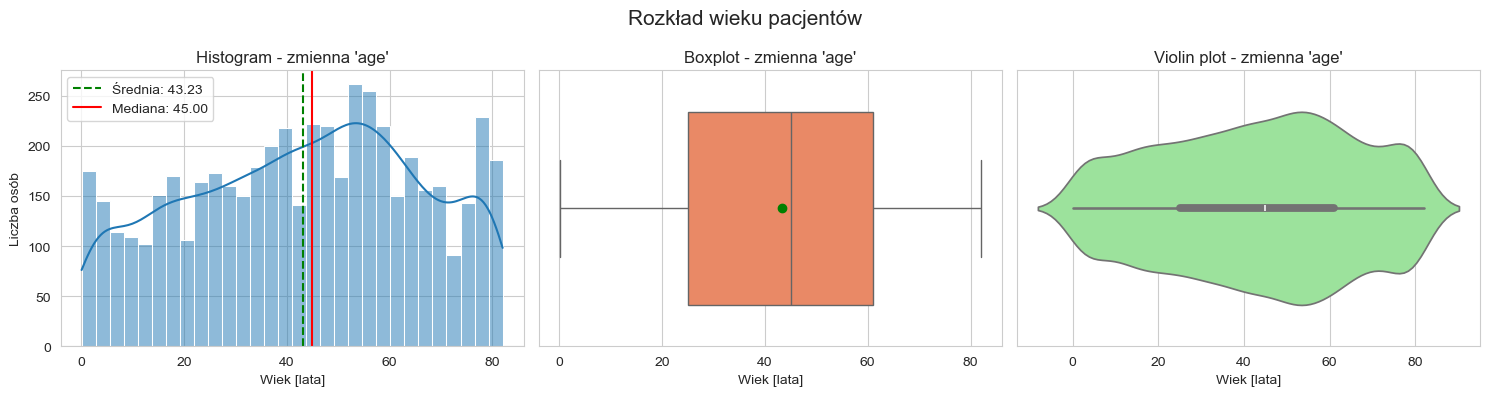

In [17]:
wykresy_dla_zm_ilosciowych(df, 'age', 'Rozkład wieku pacjentów', 'Wiek','lata')

**5.2 Rozkład wartości średniego poziomu glukozy pacjentów**

Rozkład jest wyraźnie prawostronnie skośny. Widoczne są dwa skupiska wartości: pierwsze dominujące przy 70-90 mg/dL (pacjenci z poziomem glukozy w normie) oraz drugie, mniejsze, w okolicach 200-250 mg/dL (prawdopodobnie pacjenci z cukrzycą). Ta dwumodalność jest wyraźnie widoczna zarówno na histogramie (widoczne as dwa szczyty), jak i na wykresie violin plot (widoczne są dwa zgrubienia kształtu skrzypiec odpowiadające dwóm skupiskom wartości). Boxplot ujawnia wiele wartości odstających powyżej 170 mg/dL. Średnia (106,14) jest znacznie wyższa od mediany (91,88), co potwierdza wpływ wysokich wartości średniej. 

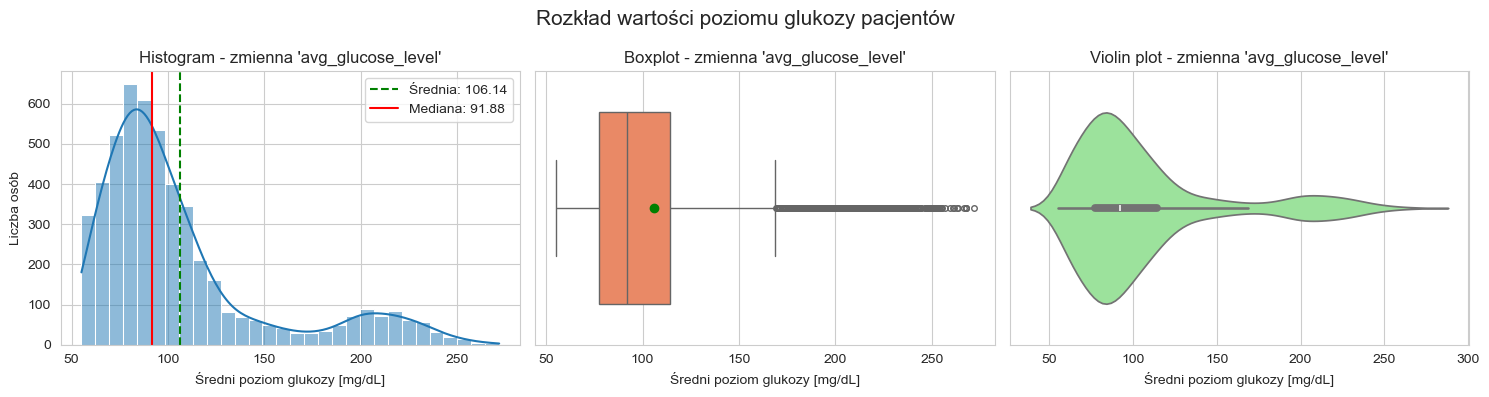

In [18]:
wykresy_dla_zm_ilosciowych(df, 'avg_glucose_level', 'Rozkład wartości poziomu glukozy pacjentów', 
                           'Średni poziom glukozy', 'mg/dL')

**5.3 Rozkład wartości wskaźnika BMI**

Rozkład BMI jest prawostronnie skośny z wyraźnym szczytem przy wartościach 25-30 kg/m^2. Pudełko w boxplocie jest stosunkowo wąskie względem całego zakresu skali - środkowe 50% danych jest mocno skupione, podczas gdy wartości odstające są bardzo odległe od reszty. Boxplot i violin plot wskazują na liczne przypadki skrajnej otyłości (BMI powyżej 50 kg/m^2). 

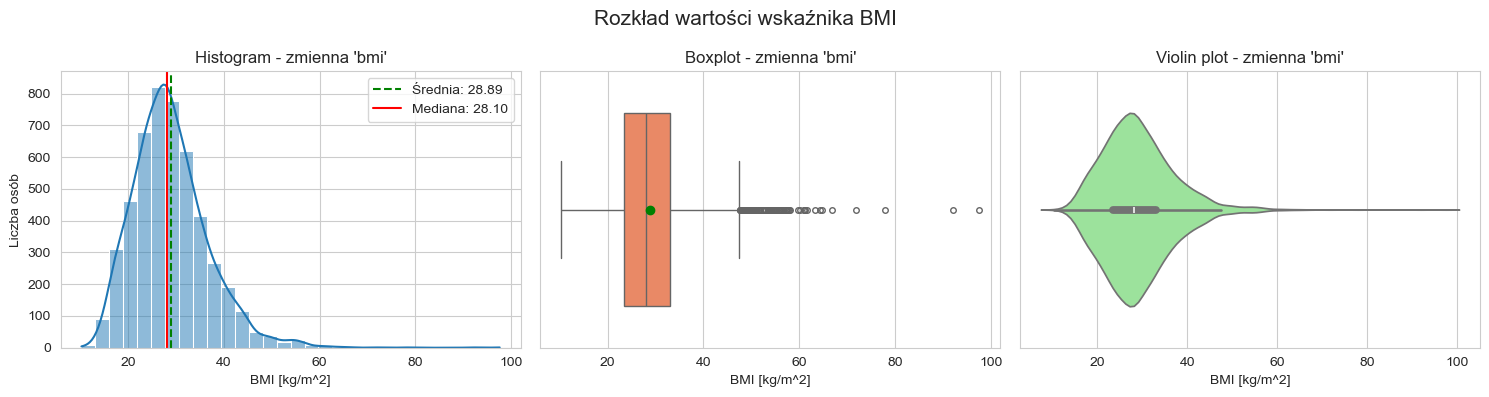

In [19]:
wykresy_dla_zm_ilosciowych(df, 'bmi', 'Rozkład wartości wskaźnika BMI','BMI', 'kg/m^2')

**5.4 Rozkłady wybranych cech jakościowych**

**Pie charts:**
- **gender**: w zbiorze nieznacznie dominują kobiety (58,6% vs 41,4% mężczyzn) - różnica jest umiarkowana i nie wskazuje na silną dysproporcję. 
- **ever_married**: większość pacjentów była kiedykolwiek zamężna/żonata (65,6%), co może być powiązane z relatywnie starszym profilem wiekowym zbioru. 
- **hypertension** oraz **heart_disease**: zdecydowana większość pacjentów nie ma nadciśnienia (90,3%) ani chorób serca (94,6%) - obie cechy kliniczne dotyczą wyraźnej mniejszości, jednak należy mieć je szczególnie na uwadzę jako, że są to znane czynniki ryzyka udaru.

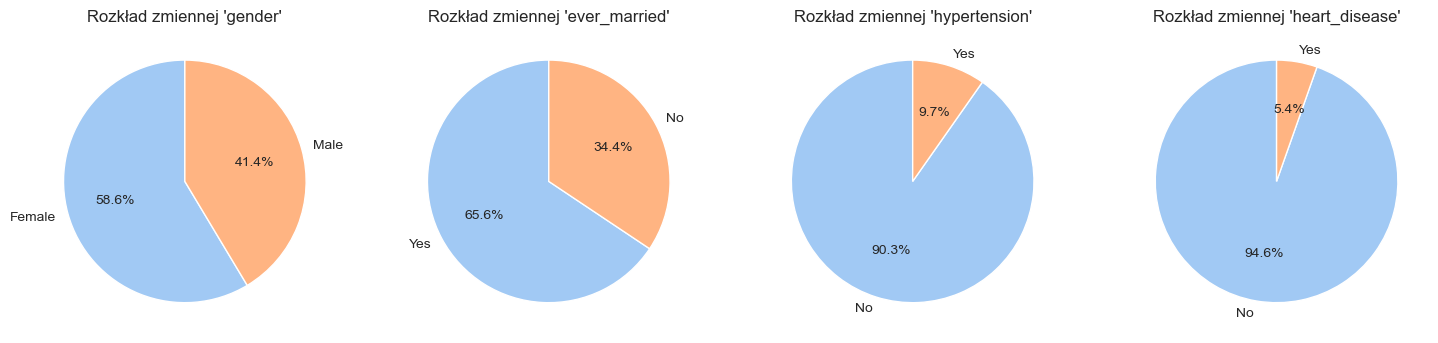

In [20]:
cols= ['gender', 'ever_married','hypertension', 'heart_disease',  ]
labels = [['Female', 'Male'], ['Yes', 'No'], ['No', 'Yes'], ['No', 'Yes']]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, labels in zip(axes, cols, labels):
    counts = df[col].value_counts()
    ax.pie(counts, labels=labels, autopct='%1.1f%%',startangle=90, colors=sns.color_palette('pastel'))
    ax.set_title(f'Rozkład zmiennej \'{col}\'')
plt.show()

**Barplots**
- **work_type**: najliczniejszą grupą zawodową są pracownicy sektora prywatnego. Pozostałe kategorie (samozatrudnieni, dzieci, sektor publiczny) są zbliżone liczebnie, natomiast kategoria Never_worked jest marginalna i praktycznie niewidoczna na wykresie. 
- **smoking_status**: w przypadku statusu palenia największą grupę stanowią osoby, które nigdy nie paliły. Bardzo wysoki udział kategorii Unknown, co istotnie ogranicza możliwości analizy wpływu palenia na ryzyko udaru.

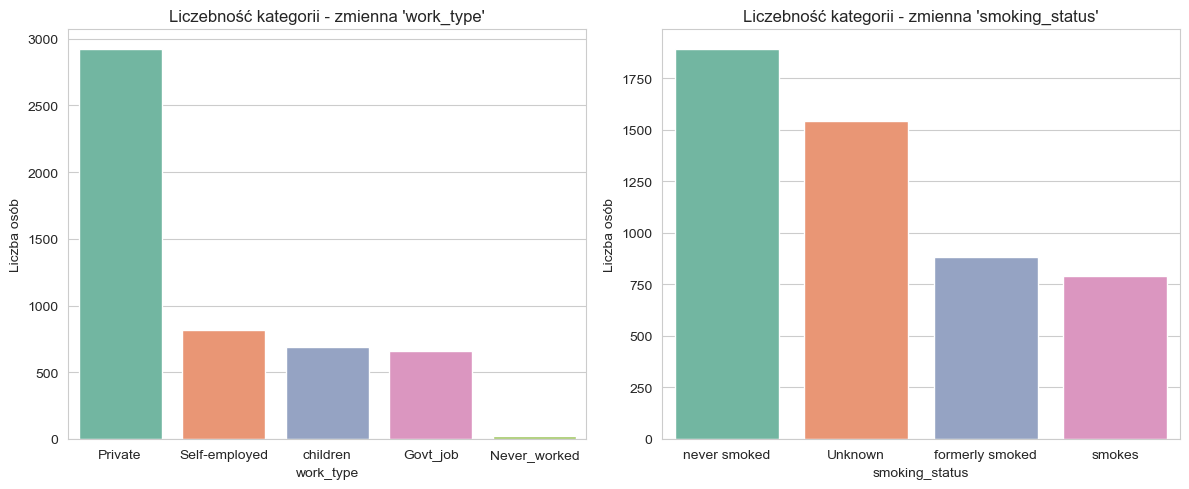

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ['work_type', 'smoking_status']):
    counts = df[col].value_counts()
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Set2')
    ax.set_title(f'Liczebność kategorii - zmienna \'{col}\'')
    ax.set_xlabel(col)
    ax.set_ylabel('Liczba osób')

plt.tight_layout()
plt.show()

**Zmienna docelowa**

Wykres wyraźnie ilustruje silny niebalans zmiennej docelowej - zaledwie 4,9% pacjentów doświadczyło udaru mózgu. Mimo, że udar mózgu należy do jednej z najczęstszych przyczyn śmierci, to tak duża nierównowaga klas odzwierciedla rzeczywistość kliniczną, tzn. udar jest zdarzeniem poważnym, ale w populacji ogólnej jest stosunkowo rzadki.

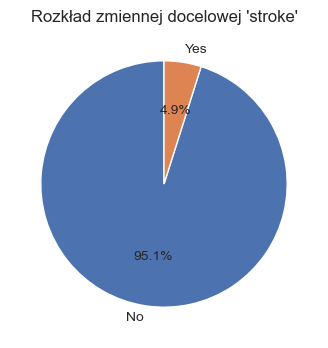

In [22]:
counts = df['stroke'].value_counts()

plt.figure(figsize=(4,4))
plt.pie(counts, labels=['No', 'Yes'], autopct='%1.1f%%',startangle=90, colors=sns.color_palette('deep'))
plt.title(f'Rozkład zmiennej docelowej \'stroke\'')
plt.show()

## 6. Porównanie względem cechy jakościowej 
**Analiza porównawcza rozkładu wieku, średniego poziomu glukozy i BMI wg wystąpienia udaru mózgu**

age               avg_glucose_level                   bmi         \
         mean median    std              mean  median    std   mean median   
stroke                                                                       
0       41.97   43.0  22.29            104.79   91.46  43.85  28.82   28.0   
1       67.73   71.0  12.73            132.54  105.22  61.92  30.47   29.7   

              
         std  
stroke        
0       7.91  
1       6.33

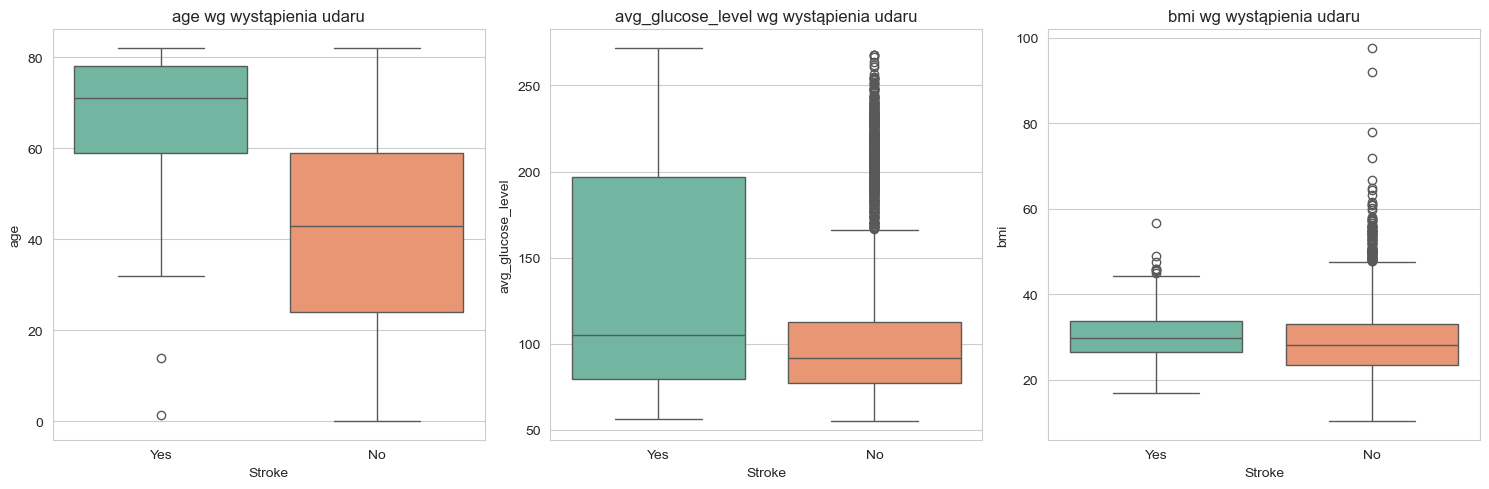

In [23]:
# Tabela statystyk w grupach
tabela_stat = df.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].agg(['mean', 'median', 'std'])
display(tabela_stat.round(2))

# Wykres porównawczy - boxplot wg stroke
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    sns.boxplot(data=df, x=df['stroke'].map({0: 'No', 1: 'Yes'}), y=col, ax=ax, palette='Set2')
    ax.set_title(f'{col} wg wystąpienia udaru')
    ax.set_xlabel('Stroke')
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

Interpretacja:

**age** - wiek

- Średni wiek osób z udarem (67,73 lat) jest znacząco wyższy niż u osób zdrowych (41,97 lat).
- Boxplot dla grupy "Yes" jest mocno przesunięty w górę i jest znacznie krótszy (mniejsze odchylenie standardowe). Oznacza to, że udar w tym zbiorze danych dotyka głównie osob starszych i w podeszłym wieku.

**Wniosek:** Wiek jest kluczową zmienną. Osoby poniżej 35. roku życia (poza nielicznymi outlierami) znajdują się w grupie bardzo niskiego ryzyka.

<br>**avg_glucose_level** - poziom glukozy 

- Osoby po udarze mają wyraźnie wyższy średni poziom glukozy (średnia 132,54 mg/dL) w porównaniu do grupy osób zdrowych (104,79 mg/dL).
- W grupie "Yes" mediana wynosi 105,22, co oznacza, że nawet połowa pacjentów z udarem ma wyniki znacznie powyżej normy. 

**Wniosek:** Wysoki poziom cukru współwystępuje z incydentami udarowymi. Grupa "No" posiada bardzo dużo wartości odstających, co sugeruje, że wysoki cukier nie zawsze kończy się udarem, ale udar bardzo często wiąże się z wysokim poziomem glukozy.

<br>**bmi** - wskaźnik BMI 

- Jest to najmniej różnicująca zmienna spośród trzech analizowanych. Średnie BMI dla obu grup oscyluje wokół 29-30 (granica nadwagi i otyłości).
- Choć średnia dla grupy z udarem jest minimalnie wyższa, to wizualnie oba pudełka na wykresie w dużej mierze się pokrywają.

**Wniosek:** Samo wysokie BMI w analizowanym zbiorze danych nie jest tak jednoznacznym wskaźnikiem udaru jak wiek czy glukoza. W grupie zdrowej obserwujemy znacznie więcej ekstremalnych wartości odstających (osoby z BMI > 50), które mimo otyłości nie doznały udaru.

## 7. Analiza zależności między zmiennymi 

**7.1 Zależność między wiekiem a poziomem glukozy (age vs avg_glucose_level)**

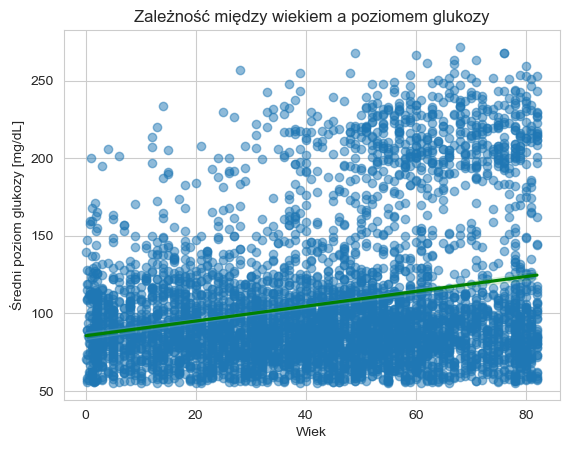

Współczynnik korelacji 0.23832284089017206


In [24]:
sns.regplot(data=df, x='age', y='avg_glucose_level', scatter_kws={"alpha":0.5}, line_kws=dict(color="g"))
plt.title('Zależność między wiekiem a poziomem glukozy')
plt.xlabel('Wiek')
plt.ylabel('Średni poziom glukozy [mg/dL]')
plt.show()

print("Współczynnik korelacji", df['age'].corr(df['avg_glucose_level']))

Interpretacja:

Na wykresie rozrzutu widoczna jest dodatnia zależność pomiędzy wiekiem a średnim poziomem glukozy we krwi. Współczynnik korelacji wynosi 0,238, co wskazuje na słabą dodatnią korelację. Oznacza to, że wraz ze wzrostem wieku pacjentów obserwuje się tendencję do nieznacznego wzrostu poziomu glukozy, jednak zależność ta nie jest silna. Na wykresie widać także duże rozproszenie punktów, co sugeruje, że wiek nie jest jedynym czynnikiem wpływającym na poziom glukozy. Można jednak zauważyć, że bardzo wysokie wartości glukozy częściej pojawiają się u osób starszych.


In [25]:
def plot_categorical_vs_stroke(df, column, title, figsize, deg=0, colors=("grey", "coral")):
    
    tabela = pd.crosstab(df[column], df['stroke'].map({0: 'No', 1: 'Yes'}), normalize='index')
    display(tabela.round(3))
    
    tabela.plot(
        kind='bar',
        stacked=True,
        figsize=figsize,
        color=colors
    )
    
    plt.title(title)
    plt.ylabel('Proporcja')
    plt.xlabel(column)
    plt.xticks(rotation=deg)
    plt.legend(title='Stroke', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

**7.2 Zależność między statusem palenia a wystąpieniem udaru mózgu (smoking_status vs stroke)**

stroke,No,Yes
smoking_status,,
Unknown,0.970,0.030
formerly smoked,0.921,0.079
never smoked,0.952,0.048
smokes,0.947,0.053


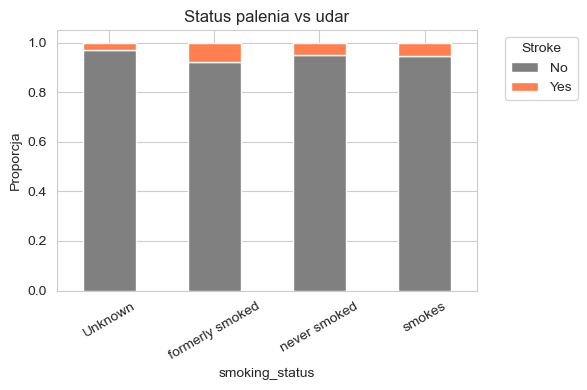

In [26]:
plot_categorical_vs_stroke(df, 'smoking_status', 'Status palenia vs udar', (6,4), 30)

Interpretacja:

Analiza wskazuje, że największy udział udarów występuje w grupie osób, które wcześniej paliły (7,9%). W grupie aktualnie palących udział udarów wynosi 5,3%, natomiast wśród osób, które nigdy nie paliły, 4,8%. 
Różnice między grupami nie są bardzo duże, jednak widoczna jest tendencja wskazująca, że osoby mające kontakt z paleniem tytoniu (obecnie lub w przeszłości) częściej doświadczają udaru niż osoby nigdy niepalące. Może to sugerować długoterminowy wpływ palenia na zdrowie układu krążenia.

**7.3 Zależność między płcią a wystąpieniem udaru mózgu (gender vs stroke)**

stroke,No,Yes
gender,,
Female,0.953,0.047
Male,0.949,0.051


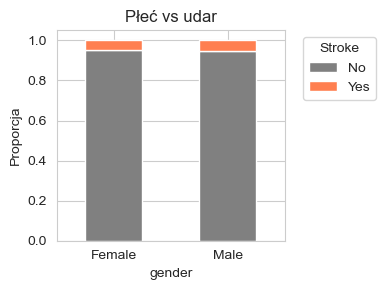

In [27]:
plot_categorical_vs_stroke(df, 'gender', 'Płeć vs udar', (4,3))

Interpretacja:

Na podstawie tabeli oraz wykresu można zauważyć, że udział pacjentów, którzy doświadczyli udaru jest bardzo zbliżony w obu grupach płci. Zatem płeć nie wydaje się być istotnym czynnikiem różnicującym ryzyko udaru w analizowanych danych.

**7.4 Zależność między stanem cywilnym a wystąpieniem udaru mózgu (ever_married vs stroke)**

stroke,No,Yes
ever_married,,
No,0.983,0.017
Yes,0.934,0.066


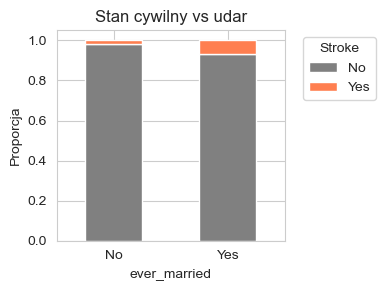

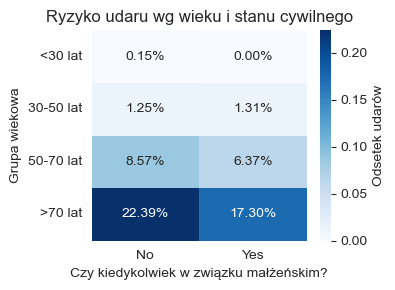

In [28]:
plot_categorical_vs_stroke(df, 'ever_married', 'Stan cywilny vs udar', (4,3))

bins = [0, 30, 50, 70, 90]
labels = ['<30 lat', '30-50 lat', '50-70 lat', '>70 lat']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)

pivot_table = df.pivot_table(index='age_group', columns='ever_married', values='stroke', aggfunc='mean')

plt.figure(figsize=(4,3))
sns.heatmap(pivot_table, annot=True, fmt=".2%", cmap="Blues", cbar_kws={'label': 'Odsetek udarów'})
plt.title('Ryzyko udaru wg wieku i stanu cywilnego')
plt.xlabel('Czy kiedykolwiek w związku małżeńskim?')
plt.ylabel('Grupa wiekowa')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Interpretacja:

Wśród osób, które nigdy nie były w związku małżeńskim, odsetek udarów wynosi zaledwie 1,7%, natomiast w grupie osób, które zawarły związek małżeński, odsetek ten wzrasta do 6,6%. Mogłoby się wydawać, że małżeństwo zwiększa ryzyko udaru. Jednakże analiza wewnątrz grup wiekowych (drugi wykres) wykazała, że była to zależność pozorna - stan cywilny nie zwiększa ryzyka udaru, a w grupach starszych osób bycie w związku koreluje wręcz z niższą częstotliwością występowania udarów mózgu.

**7.5 Zależność między nadciśnieniem a wystąpieniem udaru mózgu (hypertension vs stroke)**

stroke,No,Yes
hypertension,,
0,0.960,0.040
1,0.867,0.133


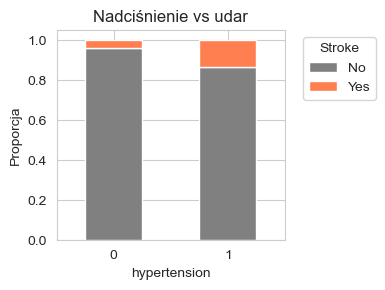

In [29]:
plot_categorical_vs_stroke(df, 'hypertension', 'Nadciśnienie vs udar', (4,3))

Interpretacja:

Wśród osób bez nadciśnienia (0) udar wystąpił u 4% badanych. Wśród osób z nadciśnieniem (1) wskaźnik ten wzrasta do ponad 13,3%. Zatem ryzyko wystąpienia udaru u osób z nadciśnieniem jest ponad 3-krotnie wyższe niż u osób ze zdrowym układem krwionośnym. 

## 8. Wnioski końcowe 

**Typowe wartości analizowanych cech**

Typowi pacjenci w zbiorze to osoby w średnim wieku (mediana 45 lat), z poziomem glukozy w normie (mediana 91,88 mg/dL) oraz BMI wskazującym na nadwagę (mediana 28,1 kg/m^2). Dominują osoby pracująca w sektorze prywatnym, które były/są w związku małżeńskim, bez nadciśnienia i chorób serca.

**Zróżnicowanie danych**

Największe zróżnicowanie wykazuje zmienna **age** oraz **avg_glucose_level**, co odzwierciedla dużą różnorodność pacjentów pod względem wieku i stanu metabolicznego.

**Obserwacje odstające**

Wartości odstające występują głównie w zmiennych **avg_glucose_level** (wartości powyżej 170 mg/dL, wskazujące na cukrzycę) oraz **bmi** (kilka przypadków skrajnej otyłości powyżej 50 kg/m^2). Zdecydowano o pozostawieniu ich w zbiorze, ponieważ są klinicznie możliwe.

**Różnice między grupami**

Najsilniejsze różnice między pacjentami z udarem i bez udaru zaobserwowano dla wieku (średnia 67,73 vs 41,97 lat) oraz poziomu glukozy (132,54 vs 104,79 mg/dL). BMI różnicuje grupy w znacznie mniejszym stopniu. Nadciśnienie okazało się istotnym czynnikiem ryzyka - wśród osób z nadciśnieniem udar wystąpił ponad 3-krotnie częściej niż u osób zdrowych.

**Zaobserwowane zależności**

Wiek jest najsilniejszym czynnikiem związanym z udarem - niemal wszystkie przypadki udaru dotyczą osób po 35. roku życia. Wysoki poziom glukozy współwystępuje z udarem, choć korelacja między wiekiem a glukozą jest słaba. Palenie tytoniu wykazuje niewielki związek z ryzykiem udaru - najwyższy odsetek udarów odnotowano wśród byłych palaczy. Płeć nie różnicuje istotnie ryzyka udaru w analizowanym zbiorze.